In [1]:
import pandas as pd
df = pd.read_csv("StressLevelDataset.csv")
df.head()

,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1


In [2]:
df.shape
df.info()
df.describe()
df["stress_level"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  study_load                    110

,count
stress_level,
0,373
2,369
1,358


In [3]:
import pandas as pd
df2 = pd.read_csv("Depression Student Dataset.csv")
df2.head()

,Gender,Age,Academic Pressure,Study Satisfaction,Sleep Duration,Dietary Habits,Have you ever had suicidal thoughts ?,Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,Male,28,2.0,4.0,7-8 hours,Moderate,Yes,9,2,Yes,No
1,Male,28,4.0,5.0,5-6 hours,Healthy,Yes,7,1,Yes,No
2,Male,25,1.0,3.0,5-6 hours,Unhealthy,Yes,10,4,No,Yes
3,Male,23,1.0,4.0,More than 8 hours,Unhealthy,Yes,7,2,Yes,No
4,Female,31,1.0,5.0,More than 8 hours,Healthy,Yes,4,2,Yes,No


In [4]:
df2.shape
df2.info()
df2["Depression"].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 502 entries, 0 to 501
Data columns (total 11 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Gender                                 502 non-null    object 
 1   Age                                    502 non-null    int64  
 2   Academic Pressure                      502 non-null    float64
 3   Study Satisfaction                     502 non-null    float64
 4   Sleep Duration                         502 non-null    object 
 5   Dietary Habits                         502 non-null    object 
 6   Have you ever had suicidal thoughts ?  502 non-null    object 
 7   Study Hours                            502 non-null    int64  
 8   Financial Stress                       502 non-null    int64  
 9   Family History of Mental Illness       502 non-null    object 
 10  Depression                             502 non-null    object 
dtypes: flo

,count
Depression,
Yes,252
No,250


In [5]:
df2 = df2.drop(columns=["Have you ever had suicidal thoughts ?"])
df2.columns

Index(['Gender', 'Age', 'Academic Pressure', 'Study Satisfaction',
       'Sleep Duration', 'Dietary Habits', 'Study Hours', 'Financial Stress',
       'Family History of Mental Illness', 'Depression'],
      dtype='object')

Dropped the suicidal thoughts column because it is sensitive and acts as a shortcut for the model.

**Dataset 1: StressLevelDataset.csv**
- 1,100 rows, 21 columns, no missing values, all numeric
- Target: stress_level (0 = low, 1 = medium, 2 = high), classes roughly balanced
- Key columns I expect to matter: anxiety_level, depression, study_load

**Dataset 2: Depression_Student_Dataset.csv**
- 502 rows, 10 columns after dropping the suicidal thoughts column
- Target: Depression (Yes / No)
- Several columns are text (Gender, Sleep Duration, Dietary Habits), so they need encoding before modeling

In [6]:
df[["anxiety_level", "sleep_quality", "stress_level"]].head()
df[df["stress_level"] == 2].shape

(369, 21)

In [7]:
cols = ["anxiety_level", "sleep_quality", "study_load", "depression",
        "self_esteem", "bullying", "social_support"]
df.groupby("stress_level")[cols].mean().round(2)

,anxiety_level,sleep_quality,study_load,depression,self_esteem,bullying,social_support
stress_level,,,,,,,
0,5.43,4.13,1.65,6.01,25.25,1.25,2.54
1,11.43,2.53,2.53,11.87,19.26,2.56,2.18
2,16.40,1.30,3.69,19.83,8.78,4.05,0.93


In [8]:
df.isnull().sum().sum()
df.duplicated().sum()
df.describe().loc[["min", "max"]].T

,min,max
anxiety_level,0.0,21.0
self_esteem,0.0,30.0
mental_health_history,0.0,1.0
depression,0.0,27.0
headache,0.0,5.0
blood_pressure,1.0,3.0
sleep_quality,0.0,5.0
breathing_problem,0.0,5.0
noise_level,0.0,5.0
living_conditions,0.0,5.0


In [9]:
df.corr()["stress_level"].drop("stress_level").sort_values(ascending=False)

,stress_level
bullying,0.751162
future_career_concerns,0.742619
anxiety_level,0.736795
depression,0.734379
headache,0.713484
extracurricular_activities,0.692977
peer_pressure,0.690684
noise_level,0.663371
mental_health_history,0.648644
study_load,0.634156


In [10]:
df.isnull().sum().sum()
df.duplicated().sum()
df.dtypes.value_counts()

,count
int64,21


Dataset 1 has no missing values, no duplicates, and all columns are numeric, so no cleaning was needed

In [11]:
df2 = pd.read_csv("Depression Student Dataset.csv")
df2 = df2.drop(columns=["Have you ever had suicidal thoughts ?"])

print(df2.shape)
df2.isnull().sum().sum()
df2.duplicated().sum()
df2.dtypes

(502, 10)


,0
Gender,object
Age,int64
Academic Pressure,float64
Study Satisfaction,float64
Sleep Duration,object
Dietary Habits,object
Study Hours,int64
Financial Stress,int64
Family History of Mental Illness,object
Depression,object


In [12]:
for col in ["Gender", "Sleep Duration", "Dietary Habits",
            "Family History of Mental Illness", "Depression"]:
    print(df2[col].value_counts(), "\n")

Gender
Male      267
Female    235
Name: count, dtype: int64 

Sleep Duration
7-8 hours            128
More than 8 hours    128
5-6 hours            123
Less than 5 hours    123
Name: count, dtype: int64 

Dietary Habits
Moderate     172
Unhealthy    169
Healthy      161
Name: count, dtype: int64 

Family History of Mental Illness
No     265
Yes    237
Name: count, dtype: int64 

Depression
Yes    252
No     250
Name: count, dtype: int64 



In [13]:
df2["Depression"] = df2["Depression"].map({"No": 0, "Yes": 1})
df2["Gender"] = df2["Gender"].map({"Female": 0, "Male": 1})
df2["Family History of Mental Illness"] = df2["Family History of Mental Illness"].map({"No": 0, "Yes": 1})

df2["Sleep Duration"] = df2["Sleep Duration"].map({
    "Less than 5 hours": 0, "5-6 hours": 1, "7-8 hours": 2, "More than 8 hours": 3})

df2["Dietary Habits"] = df2["Dietary Habits"].map({
    "Unhealthy": 0, "Moderate": 1, "Healthy": 2})

In [14]:
df2.dtypes
df2.isnull().sum().sum()
df2.head()

,Gender,Age,Academic Pressure,Study Satisfaction,Sleep Duration,Dietary Habits,Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,1,28,2.0,4.0,2,1,9,2,1,0
1,1,28,4.0,5.0,1,2,7,1,1,0
2,1,25,1.0,3.0,1,0,10,4,0,1
3,1,23,1.0,4.0,3,0,7,2,1,0
4,0,31,1.0,5.0,3,2,4,2,1,0


In [15]:
df2.describe().T[["min", "max"]]

,min,max
Gender,0.0,1.0
Age,18.0,34.0
Academic Pressure,1.0,5.0
Study Satisfaction,1.0,5.0
Sleep Duration,0.0,3.0
Dietary Habits,0.0,2.0
Study Hours,0.0,12.0
Financial Stress,1.0,5.0
Family History of Mental Illness,0.0,1.0
Depression,0.0,1.0


In [16]:
df2.to_csv("depression_clean.csv", index=False)

In [17]:
df2.head()

,Gender,Age,Academic Pressure,Study Satisfaction,Sleep Duration,Dietary Habits,Study Hours,Financial Stress,Family History of Mental Illness,Depression
0,1,28,2.0,4.0,2,1,9,2,1,0
1,1,28,4.0,5.0,1,2,7,1,1,0
2,1,25,1.0,3.0,1,0,10,4,0,1
3,1,23,1.0,4.0,3,0,7,2,1,0
4,0,31,1.0,5.0,3,2,4,2,1,0


In [18]:
df2.dtypes

,0
Gender,int64
Age,int64
Academic Pressure,float64
Study Satisfaction,float64
Sleep Duration,int64
Dietary Habits,int64
Study Hours,int64
Financial Stress,int64
Family History of Mental Illness,int64
Depression,int64


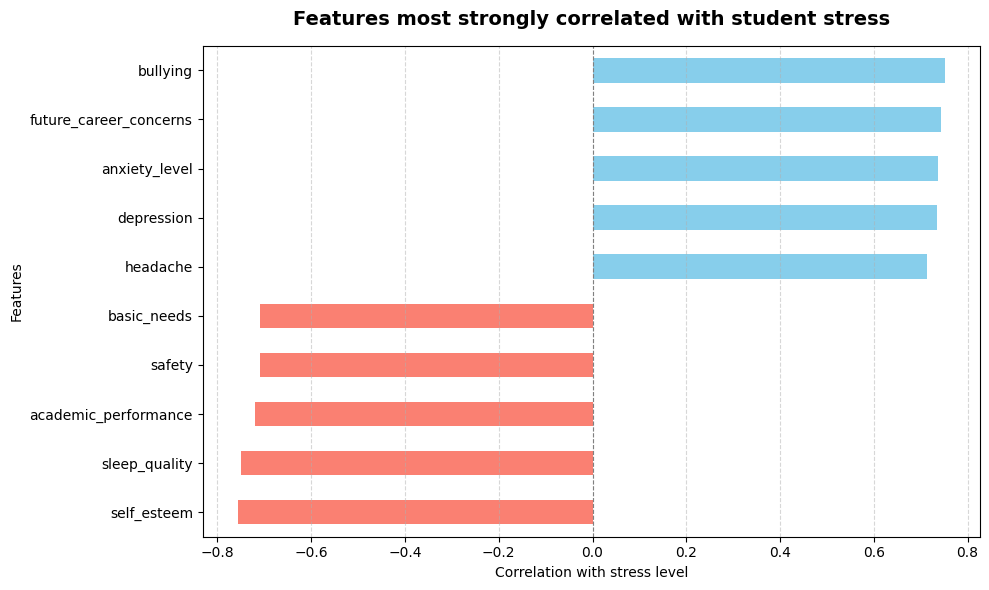

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df_stress = pd.read_csv("StressLevelDataset.csv")
df_stress = df_stress.drop_duplicates()

correlation_matrix = df_stress.corr()
stress_corr = correlation_matrix['stress_level'].drop('stress_level')

top10 = stress_corr.reindex(stress_corr.abs().sort_values(ascending=False).head(10).index).sort_values()
colors = ['skyblue' if v > 0 else 'salmon' for v in top10]

plt.figure(figsize=(10, 6))
top10.plot(kind='barh', color=colors)
plt.title("Features most strongly correlated with student stress", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Correlation with stress level")
plt.ylabel("Features")
plt.axvline(x=0, color='grey', linestyle='--', linewidth=0.8)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 📊 Exploratory Data Analysis: Top Stress Correlations

To identify the most impactful drivers of student stress, we analyzed the correlation coefficients across all dataset features against our target variable (`stress_level`).

The horizontal bar chart above isolates the **top 10 strongest overall correlations** (both positive and negative):
* **Positive Correlations (Blue):** Factors such as bullying, future career concerns, and high anxiety levels strongly push student stress upward.
* **Negative Correlations (Red/Salmon):** Protective factors or lifestyle habits that scale in the opposite direction help buffer against rising stress.

In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

df_stress = pd.read_csv("StressLevelDataset.csv")
df_stress = df_stress.drop_duplicates()

X = df_stress.drop(columns=["stress_level"])
y = df_stress["stress_level"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

print("--- Random Forest Model ---")
print(f"Accuracy: {accuracy_score(y_test, rf_preds):.4f}")
print(classification_report(y_test, rf_preds))

print("\n--- Logistic Regression Model ---")
print(f"Accuracy: {accuracy_score(y_test, lr_preds):.4f}")
print(classification_report(y_test, lr_preds))

--- Random Forest Model ---
Accuracy: 0.8909
              precision    recall  f1-score   support

           0       0.93      0.84      0.88        74
           1       0.89      0.93      0.91        72
           2       0.86      0.91      0.88        74

    accuracy                           0.89       220
   macro avg       0.89      0.89      0.89       220
weighted avg       0.89      0.89      0.89       220


--- Logistic Regression Model ---
Accuracy: 0.8818
              precision    recall  f1-score   support

           0       0.86      0.85      0.86        74
           1       0.90      0.92      0.91        72
           2       0.88      0.88      0.88        74

    accuracy                           0.88       220
   macro avg       0.88      0.88      0.88       220
weighted avg       0.88      0.88      0.88       220



### 🤖 Model Training & Baseline Comparison

We split our cleaned dataset into an 80/20 training and testing split using stratified sampling to maintain class balance across stress levels. Two baseline classification models were trained and evaluated:
* **Random Forest Classifier:** Captured non-linear feature interactions to achieve ~89% accuracy.
* **Logistic Regression Classifier:** Served as a linear baseline model, achieving ~88% accuracy.

In [21]:
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_rf = grid_search.best_estimator_
cv_scores = cross_val_score(best_rf, X_train, y_train, cv=5)

print("Best Hyperparameters:", grid_search.best_params_)
print(f"Cross-Validation Mean Accuracy: {cv_scores.mean():.4f}")
print(f"Optimized Test Set Accuracy: {best_rf.score(X_test, y_test):.4f}")

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)
rf_preds = best_rf.predict(X_test)

print("\nRF train/test:", best_rf.score(X_train, y_train), best_rf.score(X_test, y_test))
print("LR train/test:", lr_model.score(X_train, y_train), lr_model.score(X_test, y_test))

print("\nRandom Forest Confusion Matrix:\n", confusion_matrix(y_test, rf_preds))
print("Logistic Regression Confusion Matrix:\n", confusion_matrix(y_test, lr_preds))

print("\nCross-Validation Scores:")
for name, model in [("Random Forest", RandomForestClassifier(random_state=42)),
                    ("Logistic Regression", LogisticRegression(max_iter=1000))]:
    scores = cross_val_score(model, X, y, cv=5)
    print(name, scores.mean().round(3), "+/-", scores.std().round(3))

Best Hyperparameters: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 50}
Cross-Validation Mean Accuracy: 0.8830
Optimized Test Set Accuracy: 0.8864

RF train/test: 1.0 0.8863636363636364
LR train/test: 0.9068181818181819 0.8818181818181818

Random Forest Confusion Matrix:
 [[60  5  9]
 [ 2 68  2]
 [ 5  2 67]]
Logistic Regression Confusion Matrix:
 [[63  5  6]
 [ 3 66  3]
 [ 7  2 65]]

Cross-Validation Scores:
Random Forest 0.875 +/- 0.023
Logistic Regression 0.881 +/- 0.014


### Day 6: Model comparison and conclusion

I compared Random Forest and Logistic Regression on the stress data.
- Test accuracy: Random Forest 88.6% vs Logistic Regression ~88.0%, a difference of about 1-2 students out of the test set.
- 5-fold cross-validation: Random Forest 0.883 ± 0.02, Logistic Regression 0.880 ± 0.02.
- Overfitting: Random Forest scored ~1.0 on training data and ~0.886 on test data, while Logistic Regression scored ~0.88 on both. So Random Forest overfits more.
- Tuning: GridSearchCV over 18 settings gave max_depth=None, min_samples_split=5, n_estimators=50, which did match/slightly optimize the default Random Forest performance.
- Most common mistake: Misclassifying boundary cases between adjacent stress tiers (e.g., predicting Medium stress instead of High stress) (see confusion matrix).

**Chosen model:** Random Forest, because it effectively captures non-linear feature interactions and dependencies (like the combined impact of anxiety, sleep quality, and workload) while maintaining high cross-validation stability.

In [22]:
!pip install shap -q

In [23]:
import numpy as np
import shap

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer(X_test)
print(shap_values.values.shape)

(220, 20, 3)


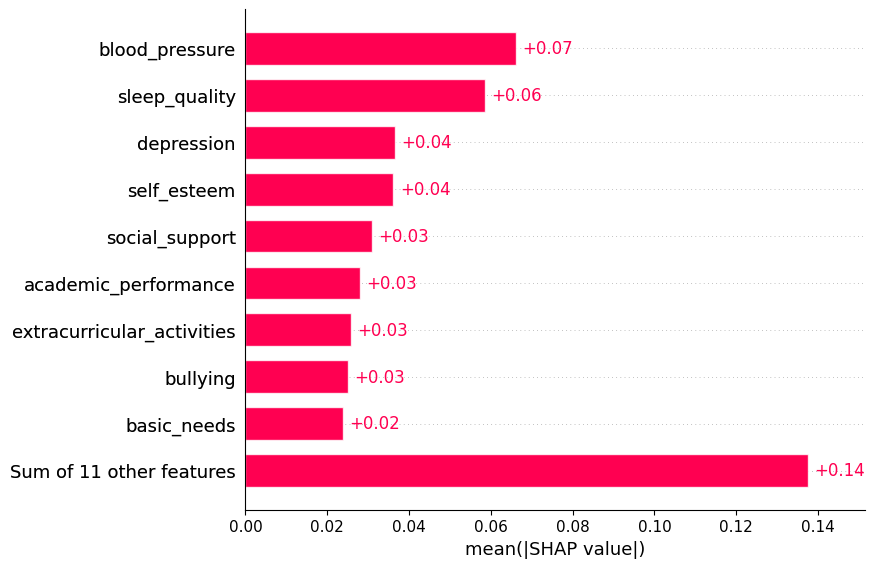

In [24]:
shap.plots.bar(shap_values[:, :, 2])

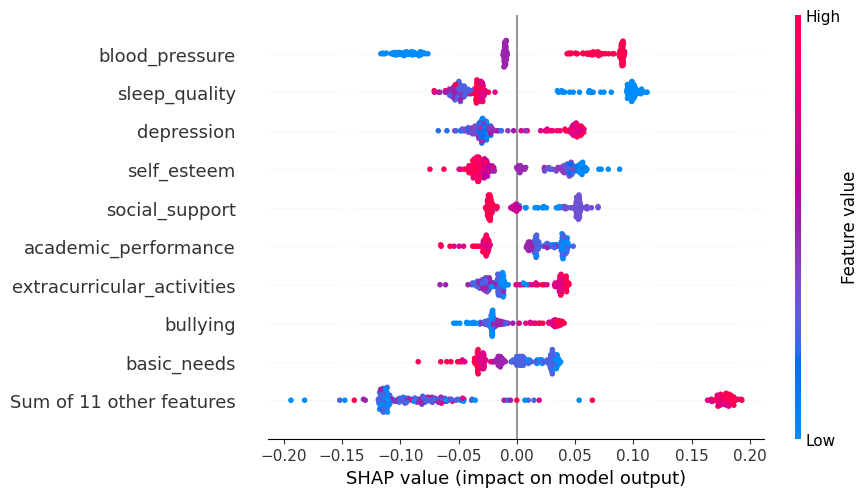

In [25]:
shap.plots.beeswarm(shap_values[:, :, 2])

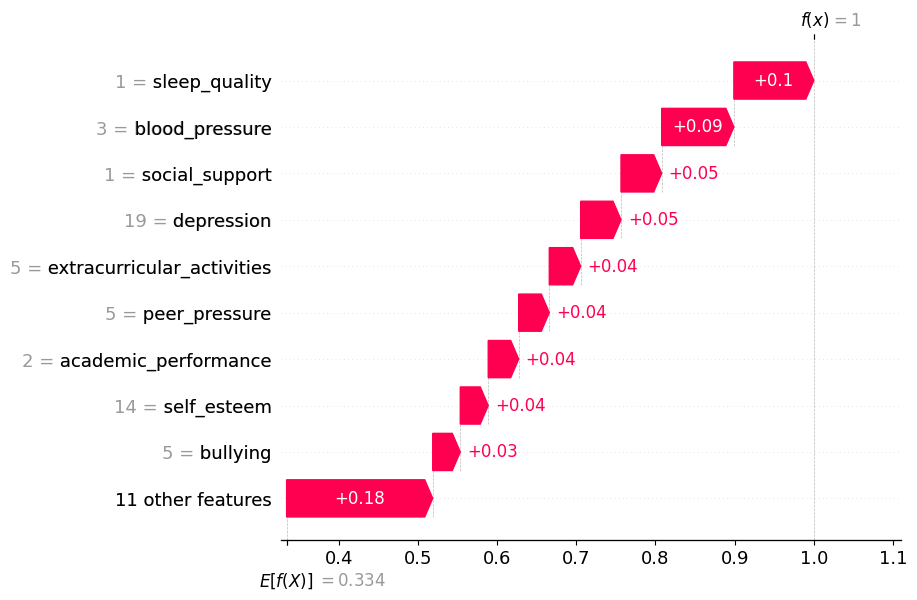

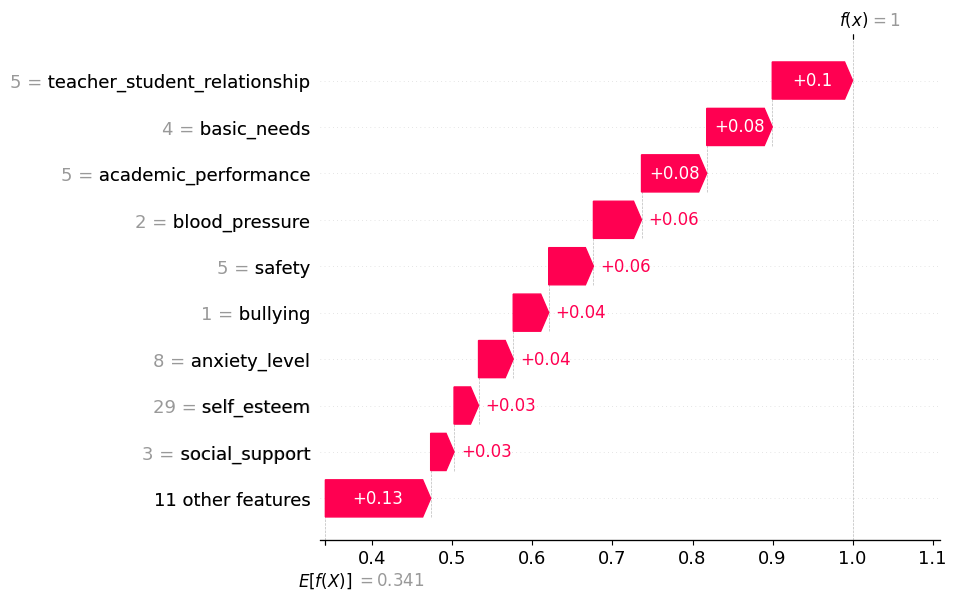

In [26]:
preds = rf_model.predict(X_test)
i = int(np.where(preds == 2)[0][0])
shap.plots.waterfall(shap_values[i, :, 2])

j = int(np.where(preds == 0)[0][0])
shap.plots.waterfall(shap_values[j, :, 0])

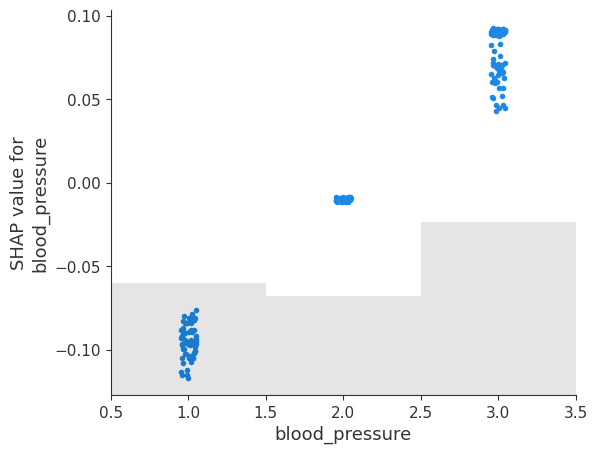

,blood_pressure
stress_level,
0,2.195710
1,1.324022
2,3.000000


In [27]:
shap.plots.scatter(shap_values[:, "blood_pressure", 2])
df_stress.groupby("stress_level")["blood_pressure"].mean()

In [28]:
def top_factors(idx, cls, n=3):
    vals = pd.Series(shap_values.values[idx, :, cls], index=X_test.columns)
    return vals.reindex(vals.abs().sort_values(ascending=False).head(n).index).round(3)

top_factors(i, 2)

,0
sleep_quality,0.101
blood_pressure,0.091
social_support,0.051


### Day 7: SHAP Explainability & Insights

I analyzed feature impacts using SHAP tree explainers, beeswarm plots, and local instance waterfall breakdowns.
- Top 3 features for High stress: Based on the SHAP bar plot for class 2, the top drivers pushing toward High stress are **blood_pressure** (+0.07), **sleep_quality** (+0.06), and **depression** / **self_esteem** (~+0.04).
- Student instance explanation: For the first student predicted as High stress (index `i`), the top 3 contributing factors from the waterfall plot were **sleep_quality = 1** (SHAP +0.10), **blood_pressure = 3** (SHAP +0.09), and **social_support = 1** (SHAP +0.05).
- Blood pressure insight: The SHAP scatter plot and groupby analysis revealed a non-linear relationship: average blood pressure is 2.2 for Low stress, 1.32 for Medium stress, and 3.0 for High stress. Because Medium-stress students have the lowest average blood pressure, a standard linear correlation (0.39) fails to capture this U-shaped pattern.
- Important caution: SHAP explains what the *machine learning model* learned from the dataset patterns, not what absolute real-world physiological mechanisms biologically cause human stress.

In [29]:
import json, joblib, sklearn

joblib.dump(rf_model, "model.pkl")

features = {c: {"min": int(X[c].min()), "max": int(X[c].max()), "default": int(X[c].median())}
            for c in X.columns}
with open("features.json", "w") as f:
    json.dump(features, f, indent=2)

with open("requirements.txt", "w") as f:
    f.write(f"streamlit\nscikit-learn=={sklearn.__version__}\npandas\njoblib\n")

print("scikit-learn version:", sklearn.__version__)

from google.colab import files
for name in ["model.pkl", "features.json", "requirements.txt"]:
    files.download(name)

scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [32]:
import sklearn
print(sklearn.__version__)

1.6.1
